In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Customer_Name': ['  Alice Smith (VIP) ', 'Bob Jones (Reg)', '  Alice Smith (VIP) ', 'charlie brown', 'DAVID MILLER', 'Bob Jones (Reg)'],
    'Region': ['East_US', 'West_US', 'East_US', 'North_EU', 'South_US', 'West_US'],
    'Revenue': [1200.50, 850.00, 1200.50, np.nan, 450.25, 850.00],
    'Cost': [400.00, 300.00, 400.00, 200.00, np.nan, 300.00],
    'Orders': [5, 3, 5, 2, 0, 3]
}
df_raw = pd.DataFrame(data)
print("--- RAW DATA (Before Cleaning) ---")
print(df_raw)
print("\n" + "="*50 + "\n")

--- RAW DATA (Before Cleaning) ---
          Customer_Name    Region  Revenue   Cost  Orders
0    Alice Smith (VIP)    East_US  1200.50  400.0       5
1       Bob Jones (Reg)   West_US   850.00  300.0       3
2    Alice Smith (VIP)    East_US  1200.50  400.0       5
3         charlie brown  North_EU      NaN  200.0       2
4          DAVID MILLER  South_US   450.25    NaN       0
5       Bob Jones (Reg)   West_US   850.00  300.0       3




In [2]:

df_clean = df_raw.drop_duplicates().copy()
df_clean['Customer_Name'] = df_clean['Customer_Name'].str.strip().str.title()
df_clean['Revenue'] = df_clean['Revenue'].fillna(df_clean['Revenue'].median())
df_clean['Cost'] = df_clean['Cost'].fillna(df_clean['Cost'].median())
df_clean['Profit'] = df_clean['Revenue'] - df_clean['Cost']
df_clean['Profit_Margin'] = np.where(df_clean['Revenue'] > 0, (df_clean['Profit'] / df_clean['Revenue']) * 100, 0)

print("--- CLEANED DATA ---")
print(df_clean)
print("\n" + "="*50 + "\n")

--- CLEANED DATA ---
       Customer_Name    Region  Revenue   Cost  Orders  Profit  Profit_Margin
0  Alice Smith (Vip)   East_US  1200.50  400.0       5  800.50      66.680550
1    Bob Jones (Reg)   West_US   850.00  300.0       3  550.00      64.705882
3      Charlie Brown  North_EU   850.00  200.0       2  650.00      76.470588
4       David Miller  South_US   450.25  300.0       0  150.25      33.370350




/tmp/ipykernel_492/379448907.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Customer_Name', y='Revenue', data=df_clean, palette='Blues_d')


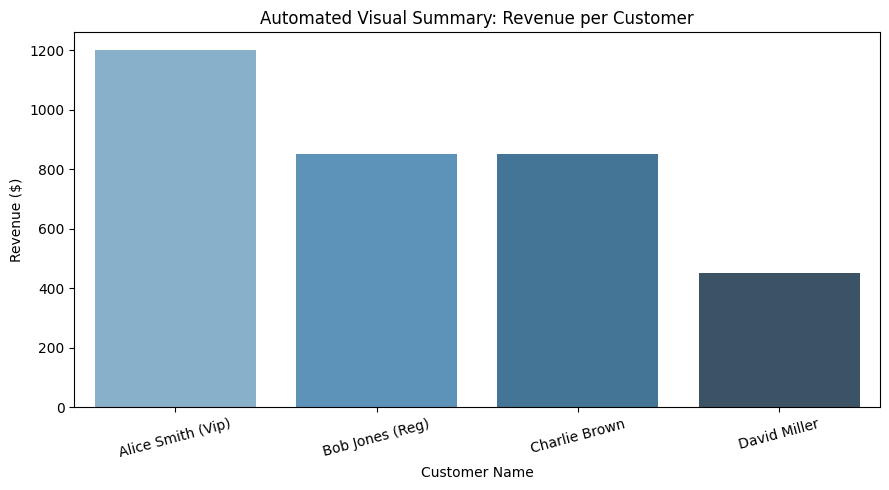

In [3]:
plt.figure(figsize=(9, 5))
sns.barplot(x='Customer_Name', y='Revenue', data=df_clean, palette='Blues_d')
plt.title('Automated Visual Summary: Revenue per Customer')
plt.xlabel('Customer Name')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('automated_visual_summary.png')
plt.show()

In [4]:
total_revenue = df_clean['Revenue'].sum()
total_profit = df_clean['Profit'].sum()
avg_margin = df_clean['Profit_Margin'].mean()

print("--- AUTOMATED BUSINESS SUMMARY REPORT ---")
print(f"Total Cleaned Records : {len(df_clean)}")
print(f"Total Revenue         : ${total_revenue:,.2f}")
print(f"Total Profit          : ${total_profit:,.2f}")
print(f"Average Profit Margin : {avg_margin:.2f}%")

--- AUTOMATED BUSINESS SUMMARY REPORT ---
Total Cleaned Records : 4
Total Revenue         : $3,350.75
Total Profit          : $2,150.75
Average Profit Margin : 60.31%


In [5]:
df_clean.to_csv('automated_cleaned_report.csv', index=False)
print("\n[SUCCESS] Cleaned report saved as 'automated_cleaned_report.csv' and chart saved as 'automated_visual_summary.png'!")


[SUCCESS] Cleaned report saved as 'automated_cleaned_report.csv' and chart saved as 'automated_visual_summary.png'!
